Notebook to explore building a network model from PG&E distribution data

## Set-Up

In [1]:
#import packages
import pandas as pd
import geopandas as gpd
import networkx as nx
from pathlib import Path

In [3]:
#set paths for sript, data, and scratch folder
script_fldr = Path.cwd() 
project_fldr = Path.cwd().parent
raw_data_fldr = project_fldr / 'Data' / 'Raw'
processed_data_fldr = project_fldr / 'Data' / 'Processed'

print(project_fldr)
print(script_fldr)
print(raw_data_fldr)
print(processed_data_fldr)

v:\GDA_Final_Project
v:\GDA_Final_Project\Scripts
v:\GDA_Final_Project\Data\Raw
v:\GDA_Final_Project\Data\Processed


## Grid Data Exploration


In [ ]:
df_grid_attributes = pd.read_csv(raw_data_fldr/'SJ_attributes.csv')

In [8]:
df_grid_attributes.shape

(94020, 30)

In [9]:
df_grid_attributes.head()

,Unnamed: 0,OBJECTID,FeederId,FeederName,globalid,CSV_LineSection,LoadCapacity_kW,voltage_kv,phase_cnt,limiting_month_hour,...,limiting_criteria_noof,limiting_month_hour_noof,limiting_criteria_pvof,limiting_month_hour_pvof,limiting_criteria_pvnoof,limiting_month_hour_pvnoof,ScreenL,Publish,Last_Update_On_Map,Shape__Length
0,0,3300,83431108,HICKS 1108,{7EE70E4A-A155-4796-98F5-AB290633652F},4192304,3475.0,12.0,3.0,7_18,...,Voltage,"2_4, 2_5, 3_1, 3_2, 3_3, 3_4, 3_5, 3_6, 4_0, 4...",Voltage,"2_4, 2_5, 3_1, 3_2, 3_3, 3_4, 3_5, 3_6, 4_0, 4...",Voltage,"2_4, 2_5, 3_1, 3_2, 3_3, 3_4, 3_5, 3_6, 4_0, 4...",Unlikely to pass,1,2026-11-02 21:44:46,42.535312
1,1,3328,83242105,MORGAN HILL 2105,{0DB87EE8-91B4-4ECB-B277-879940757C44},3090720,627.0,21.0,3.0,1_19,...,"Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,8.222034
2,2,3330,83242105,MORGAN HILL 2105,{52A1EC2D-1252-4419-AD2E-7A238C3EEEA7},3512209,762.0,21.0,3.0,7_17,...,"Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,6.757789
3,3,3333,83242105,MORGAN HILL 2105,{063D5479-2370-431C-ACDF-012B4277D1DD},4221772,0.0,21.0,3.0,"7_17, 7_18, 7_19",...,"Safety,Thermal,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Thermal,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Thermal,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,38.384703
4,4,3340,83242105,MORGAN HILL 2105,{60A8624B-1487-4F5A-8160-A506D13A77F6},3762889,1656.0,21.0,3.0,1_19,...,"Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,73.086025


In [29]:
gdf_lines = gpd.read_file(raw_data_fldr/'SJ.shp')

In [30]:
#columns 
gdf_lines.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 94020 entries, 0 to 94019
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Id        94020 non-null  int32   
 1   objectid  94020 non-null  int64   
 2   geometry  94019 non-null  geometry
dtypes: geometry(1), int32(1), int64(1)
memory usage: 1.8 MB


In [31]:
#check coord system, EPSG:26910, meters 
gdf_lines.crs

<Projected CRS: EPSG:26910>
Name: NAD83 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: North America - between 126°W and 120°W - onshore and offshore. Canada - British Columbia; Northwest Territories; Yukon. United States (USA) - California; Oregon; Washington.
- bounds: (-126.0, 30.54, -119.99, 81.8)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [36]:
#check ObjectIDs match
gdf_lines['objectid'].nunique() == df_grid_attributes['OBJECTID'].nunique()

#join attributes to shapefile
gdf_grid = gdf_lines.merge(
    right=df_grid_attributes, 
    left_on='objectid',
    right_on='OBJECTID',
    how='left') 

#inspect gdf columns
gdf_grid.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 94020 entries, 0 to 94019
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   Id                            94020 non-null  int32   
 1   objectid                      94020 non-null  int64   
 2   geometry                      94019 non-null  geometry
 3   Unnamed: 0                    94020 non-null  int64   
 4   OBJECTID                      94020 non-null  int64   
 5   FeederId                      94020 non-null  int64   
 6   FeederName                    94020 non-null  str     
 7   globalid                      94020 non-null  str     
 8   CSV_LineSection               94020 non-null  int64   
 9   LoadCapacity_kW               59971 non-null  float64 
 10  voltage_kv                    90948 non-null  float64 
 11  phase_cnt                     93972 non-null  float64 
 12  limiting_month_hour           50582 no

In [39]:
gdf_grid.head()

,Id,objectid,geometry,Unnamed: 0,OBJECTID,FeederId,FeederName,globalid,CSV_LineSection,LoadCapacity_kW,...,limiting_criteria_noof,limiting_month_hour_noof,limiting_criteria_pvof,limiting_month_hour_pvof,limiting_criteria_pvnoof,limiting_month_hour_pvnoof,ScreenL,Publish,Last_Update_On_Map,Shape__Length
0,0,3300,"LINESTRING (598521.502 4123271.378, 598509.914...",0,3300,83431108,HICKS 1108,{7EE70E4A-A155-4796-98F5-AB290633652F},4192304,3475.0,...,Voltage,"2_4, 2_5, 3_1, 3_2, 3_3, 3_4, 3_5, 3_6, 4_0, 4...",Voltage,"2_4, 2_5, 3_1, 3_2, 3_3, 3_4, 3_5, 3_6, 4_0, 4...",Voltage,"2_4, 2_5, 3_1, 3_2, 3_3, 3_4, 3_5, 3_6, 4_0, 4...",Unlikely to pass,1,2026-11-02 21:44:46,42.535312
1,0,3328,"LINESTRING (618936.224 4102119.657, 618930.207...",1,3328,83242105,MORGAN HILL 2105,{0DB87EE8-91B4-4ECB-B277-879940757C44},3090720,627.0,...,"Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,8.222034
2,0,3330,"LINESTRING (618392.213 4102140.382, 618392.805...",2,3330,83242105,MORGAN HILL 2105,{52A1EC2D-1252-4419-AD2E-7A238C3EEEA7},3512209,762.0,...,"Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,6.757789
3,0,3333,"LINESTRING (617029.103 4099303.382, 617065.631...",3,3333,83242105,MORGAN HILL 2105,{063D5479-2370-431C-ACDF-012B4277D1DD},4221772,0.0,...,"Safety,Thermal,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Thermal,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Thermal,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,38.384703
4,0,3340,"LINESTRING (619593.945 4101182.408, 619547.893...",4,3340,83242105,MORGAN HILL 2105,{60A8624B-1487-4F5A-8160-A506D13A77F6},3762889,1656.0,...,"Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...","Safety,Voltage","1_0, 1_1, 1_10, 1_11, 1_12, 1_13, 1_14, 1_15, ...",Unlikely to pass,1,2026-11-02 21:44:46,73.086025


In [38]:
gdf_grid.columns

Index(['Id', 'objectid', 'geometry', 'Unnamed: 0', 'OBJECTID', 'FeederId',
       'FeederName', 'globalid', 'CSV_LineSection', 'LoadCapacity_kW',
       'voltage_kv', 'phase_cnt', 'limiting_month_hour', 'limiting_criteria',
       'ICA_Analysis_Date', 'lica_analysis_date', 'Division', 'GenCapacity_kW',
       'GenericPVCapacity_kW', 'GenCapacity_no_OpFlex_kW',
       'GenericCapacity_no_OpFlex_kW', 'limiting_criteria_of',
       'limiting_month_hour_of', 'limiting_criteria_noof',
       'limiting_month_hour_noof', 'limiting_criteria_pvof',
       'limiting_month_hour_pvof', 'limiting_criteria_pvnoof',
       'limiting_month_hour_pvnoof', 'ScreenL', 'Publish',
       'Last_Update_On_Map', 'Shape__Length'],
      dtype='str')

### Create Clean Dataset

In [49]:
#list of desired columns
grid_columns_list = ['objectid', 'FeederId', 'FeederName', 'LoadCapacity_kW', 'voltage_kv', 'phase_cnt', 'Division', 'geometry', 'globalid']

In [ ]:
#new df with desired columns only
gdf_grid_clean = gdf_grid[grid_columns_list]

#correct datatypes
gdf_grid_clean['FeederId'] = gdf_grid_clean['FeederId'].astype('category')
gdf_grid_clean['phase_cnt'] = gdf_grid_clean['phase_cnt'].astype('category')

gdf_grid_clean.head()

gdf_grid_clean.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 94020 entries, 0 to 94019
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   objectid         94020 non-null  int64   
 1   FeederId         94020 non-null  category
 2   FeederName       94020 non-null  str     
 3   LoadCapacity_kW  59971 non-null  float64 
 4   voltage_kv       90948 non-null  float64 
 5   phase_cnt        93972 non-null  float64 
 6   Division         94020 non-null  str     
 7   geometry         94019 non-null  geometry
 8   globalid         94020 non-null  str     
dtypes: category(1), float64(3), geometry(1), int64(1), str(3)
memory usage: 11.2 MB


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

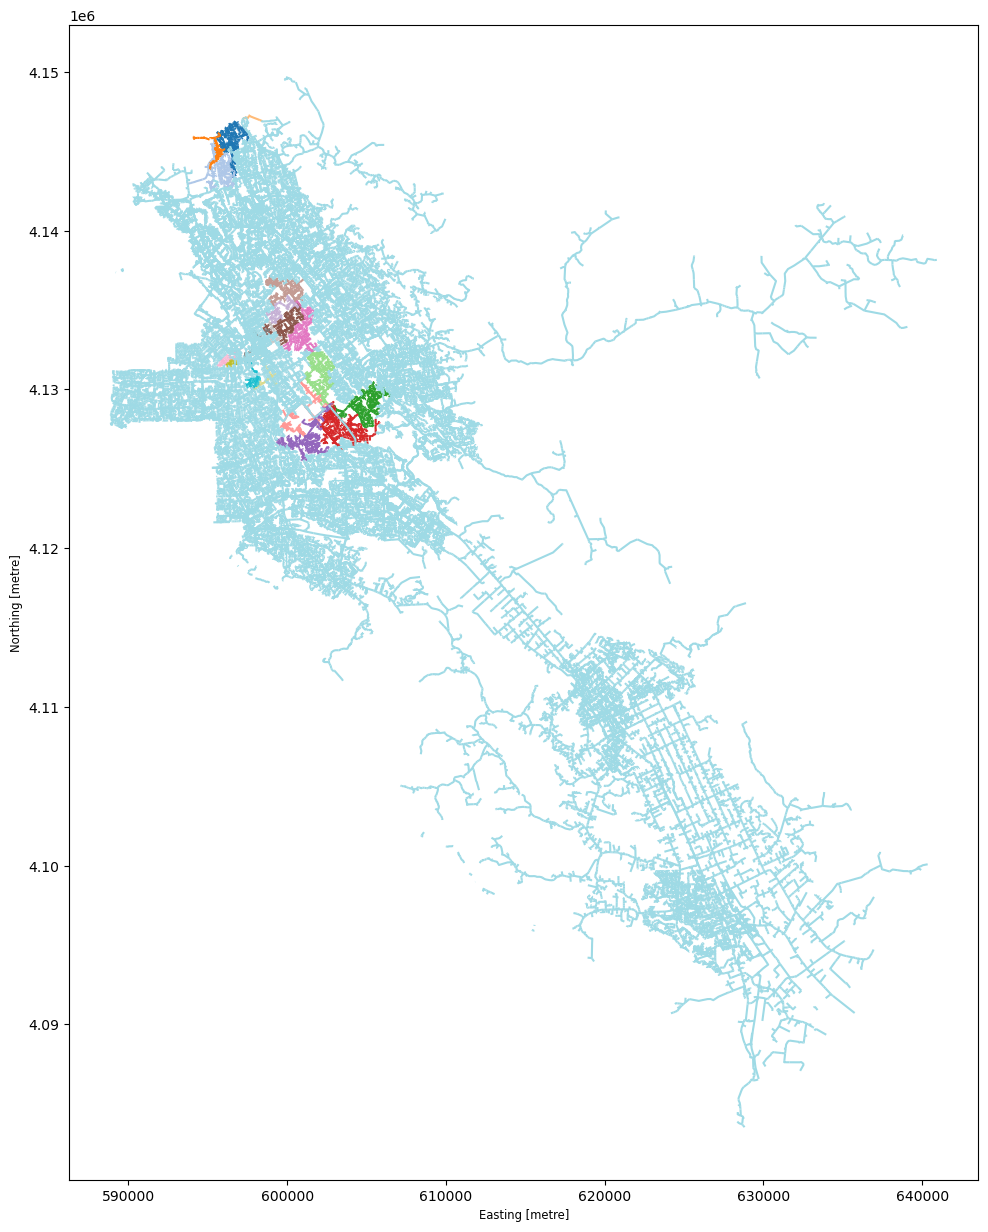

In [ ]:
gdf_grid_clean.plot('FeederId', figsize=(15,15));

## Feeder Level
There are 192 unique feeders, try dissolving on feeder ID

"The Feeder ID is a nine digit number that consists of the 5 digit Substation ID and a 4 digit Feeder Number. "Feeder" and circuit are used interchangeably within this data portal."

Need to figure out what to do with NAs (particularly w/ voltage_kv)

In [ ]:
df_grid_attributes['FeederId'].nunique()

192

In [ ]:
df_feeder = df_grid_attributes.dis

## Network Model

In [80]:
gdf_test = gpd.read_file(raw_data_fldr/'SJ.geojson')

In [ ]:
gdf_test.info()

gdf_test

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 94020 entries, 0 to 94019
Data columns (total 30 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   OBJECTID                      94020 non-null  int32   
 1   FeederId                      94020 non-null  str     
 2   FeederName                    94020 non-null  str     
 3   globalid                      94020 non-null  str     
 4   CSV_LineSection               94020 non-null  str     
 5   LoadCapacity_kW               59971 non-null  float64 
 6   voltage_kv                    90948 non-null  float64 
 7   phase_cnt                     93972 non-null  float64 
 8   limiting_month_hour           50582 non-null  str     
 9   limiting_criteria             50582 non-null  str     
 10  ICA_Analysis_Date             59836 non-null  str     
 11  lica_analysis_date            60252 non-null  str     
 12  Division                      94020 no

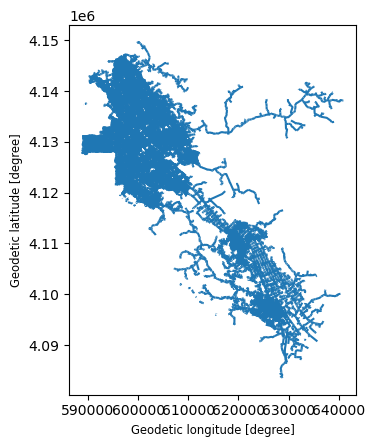

In [ ]:
gdf_test.plot()